In [1]:
import os
from collections.abc import Callable
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import seaborn as sns
import sys
sys.path.insert(0, str(Path.cwd().parent))

from src.encoder import DummyEncoder
from src import quant

HOME_DIR = Path("/Users/arnoochka/Study/Uinversity/Lossy-RAG")



/Users/arnoochka/miniconda3/envs/lossy-rag/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1111 18:04:55.908000 1420 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
data_dir = Path("../data")
chunks = pd.read_csv(data_dir / "chunks.csv")
questions = pd.read_csv(data_dir / "questions.csv")
answer_chunks = pd.read_csv(data_dir / "answer_chunks.csv")

chunks.head()

,chunk_id,pid,chunk_no,start,end,text
0,0,0,0,0,127,"Architecturally, the school has a Catholic cha..."
1,1,0,1,54,270,Atop the Main Building's gold dome is a golden...
2,2,0,2,128,333,Immediately in front of the Main Building and ...
3,3,0,3,271,421,Next to the Main Building is the Basilica of t...
4,4,0,4,334,550,"Immediately behind the basilica is the Grotto,..."


In [3]:
model_name = "BAAI/bge-small-en-v1.5"
save_dir = data_dir / f"embeddings_{model_name.rsplit('/', 1)[-1]}"

chunk_ids = np.load(save_dir / "chunk_ids.npy")
chunk_embeddings = np.load(save_dir / "chunk_embeddings.npy")
query_ids = np.load(save_dir / "query_ids.npy")
query_embeddings = np.load(save_dir / "query_embeddings.npy")

chunks = chunks.set_index("chunk_id", drop=False).loc[chunk_ids].reset_index(drop=True)
questions = questions.set_index("qid", drop=False).loc[query_ids].reset_index(drop=True)


In [4]:
encoder = DummyEncoder(
    chunk_texts=chunks["text"].tolist(),
    chunk_embeddings=chunk_embeddings,
    query_texts=questions["question"].tolist(),
    query_embeddings=query_embeddings,
)


In [5]:
def exact_search(
    query_embeddings: np.ndarray,
    chunk_embeddings: np.ndarray,
    chunk_ids: np.ndarray,
    k: int = 10,
    batch_size: int = 64,
) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает ID и оценки top-k фрагментов для каждого вопроса."""
    top_ids = []
    top_scores = []

    for start in range(0, len(query_embeddings), batch_size):
        scores = query_embeddings[start:start + batch_size] @ chunk_embeddings.T
        candidates = np.argpartition(scores, -k, axis=1)[:, -k:]
        candidate_scores = np.take_along_axis(scores, candidates, axis=1)
        order = np.argsort(-candidate_scores, axis=1)
        positions = np.take_along_axis(candidates, order, axis=1)

        top_ids.append(chunk_ids[positions])
        top_scores.append(np.take_along_axis(scores, positions, axis=1))

    return np.concatenate(top_ids), np.concatenate(top_scores)

In [6]:
K=25
if not os.path.isfile(save_dir / f"exact_top{K}_chunk_ids.npy"):
    exact_ids, exact_scores = exact_search(query_embeddings, chunk_embeddings, chunk_ids, k=K)

    np.save(save_dir / f"exact_top{K}_chunk_ids.npy", exact_ids)
    np.save(save_dir / f"exact_top{K}_scores.npy", exact_scores)
else:
    exact_ids = np.load(save_dir / f"exact_top{K}_chunk_ids.npy")
    exact_scores = np.load(save_dir / f"exact_top{K}_scores.npy")

In [7]:
def hit(retrieved: np.ndarray, relevant: set[int]) -> float:
    """Есть ли среди найденных фрагментов хотя бы один эталонный."""
    return float(len(set(retrieved) & relevant) > 0)


def precision(retrieved: np.ndarray, relevant: set[int]) -> float:
    """Доля эталонных фрагментов среди найденных."""
    retrieved_set = set(retrieved)
    return len(retrieved_set & relevant) / len(retrieved_set)


def recall(retrieved: np.ndarray, relevant: set[int]) -> float:
    """Доля найденных фрагментов среди всех эталонных."""
    return len(set(retrieved) & relevant) / len(relevant)


def mrr(retrieved: np.ndarray, relevant: set[int]) -> float:
    """Обратный ранг первого эталонного фрагмента; 0, если его нет."""
    for rank, chunk_id in enumerate(retrieved, start=1):
        if chunk_id in relevant:
            return 1.0 / rank
    return 0.0


def calculate_metrics(
    top_ids: np.ndarray,
    questions: pd.DataFrame, 
    answer_chunks: pd.DataFrame,
    metric_fn: Callable[[np.ndarray, set[int]], float],
    ks: tuple[int,...] = (1, 5, 10),
) -> pd.DataFrame:
    """Усредняет выбранную метрику по строгому и мягкому эталонам."""
    metrics = {}
    for name, gold in (
        ("strict", answer_chunks[answer_chunks["is_annotated"]]),
        ("soft", answer_chunks),
    ):
        gold_chunks = gold.groupby("orig_qid")["chunk_id"].agg(set).to_dict()
        metrics[name] = []
        for k in ks:
            values = [
                metric_fn(row[:k], gold_chunks[orig_qid])
                for orig_qid, row in zip(questions["orig_qid"], top_ids)
            ]
            metrics[name].append(np.mean(values))

    return pd.DataFrame(metrics, index=pd.Index(ks, name="k"))

In [8]:
train_mask = (questions["role"] == "train") & ~questions["is_paraphrase"]
results = {}
for metric_fn in (hit, precision, recall, mrr):
    results[metric_fn.__name__] = calculate_metrics(
        exact_ids[train_mask], questions[train_mask], answer_chunks,
        metric_fn=metric_fn, ks=(1,5,10,15,20,25),
    )

metrics = pd.concat(results, names=["metric", "k"], axis=1)
metrics

metric       hit           precision              recall                 mrr  \
k         strict      soft    strict      soft    strict      soft    strict   
k                                                                              
1       0.634024  0.639789  0.634024  0.639789  0.469188  0.451656  0.634024   
5       0.823451  0.827275  0.226515  0.232876  0.769139  0.748778  0.708448   
10      0.870679  0.873921  0.122510  0.127089  0.828908  0.810351  0.714853   
15      0.892312  0.895235  0.084473  0.088013  0.856283  0.838851  0.716562   
20      0.906046  0.908660  0.064676  0.067592  0.873499  0.856897  0.717335   
25      0.915601  0.918124  0.052509  0.054993  0.885942  0.870032  0.717755   

metric            
k           soft  
k                 
1       0.639789  
5       0.713450  
10      0.719773  
15      0.721455  
20      0.722211  
25      0.722627

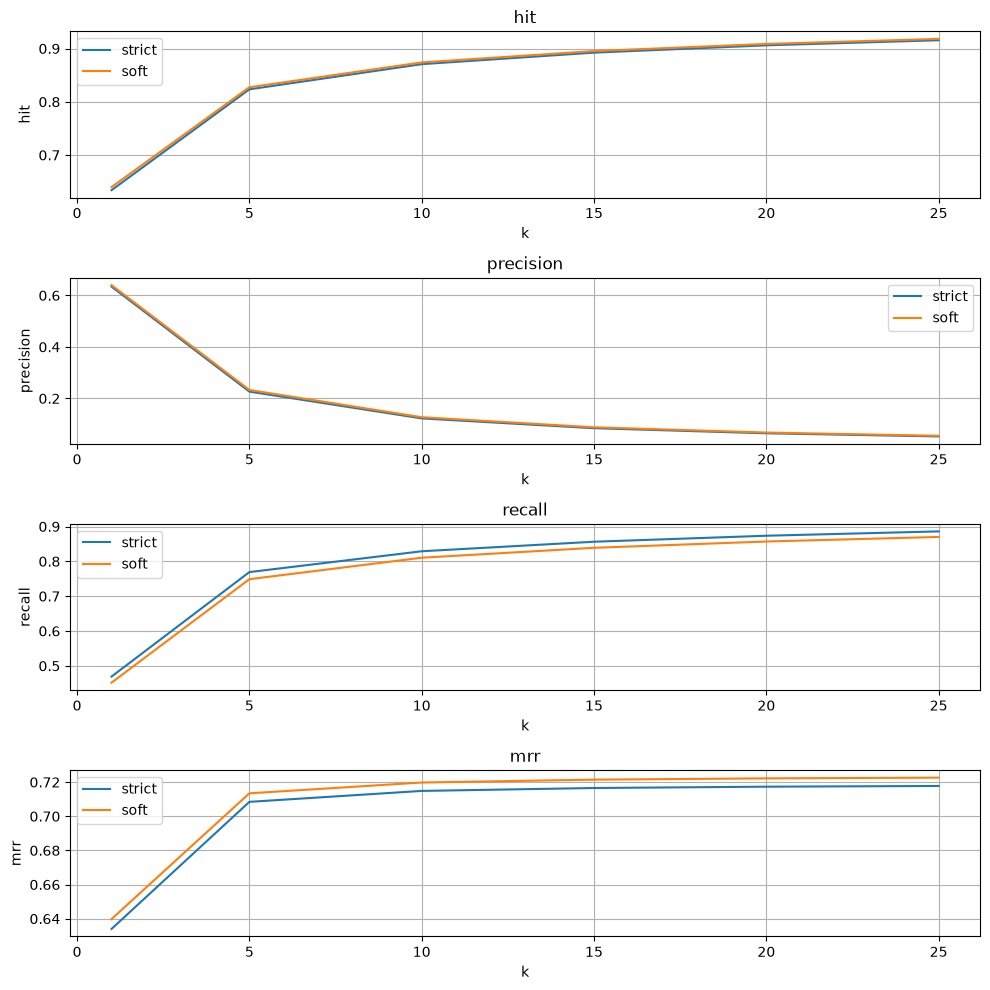

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(10, 10))

for ax, metric_name in zip(axes, ["hit", "precision", "recall", "mrr"]):
    data = metrics[metric_name].reset_index()

    sns.lineplot(data=data, x="k", y="strict", label="strict", ax=ax)
    sns.lineplot(data=data, x="k", y="soft", label="soft", ax=ax)

    ax.set_title(metric_name)
    ax.set_ylabel(metric_name)
    ax.grid(True)
    
fig.tight_layout()
plt.show()

In [12]:
def evaluate_quantization(
    query_embeddings: np.ndarray,
    chunk_embeddings: np.ndarray,
    chunk_ids: np.ndarray,
    chunks: pd.DataFrame,
    questions: pd.DataFrame,
    answer_chunks: pd.DataFrame,
    metric_fn: Callable[[np.ndarray, set[int]], float],
    quantizer: quant.BaseQuant,
    ks: tuple[int, ...] = (1, 5, 10),
) -> pd.DataFrame:
    """Обучает квантизатор на train-фрагментах и считает метрики train/valid.

    Эмбеддинги соответствуют порядку строк questions и chunks.
    Поиск идёт по всей базе без нормализации восстановленных векторов.
    Метрики исходных вопросов (real) и перефразов (paraphrase) считаются отдельно.
    """
    train_pids = questions.loc[questions["role"] == "train", "pid"]
    chunk_train_mask = chunks["pid"].isin(train_pids).to_numpy()
    quantizer.fit(chunk_embeddings[chunk_train_mask])
    codes = quantizer.quant(chunk_embeddings)
    reconstructed_embeddings = quantizer.dequant(codes)
    top_ids, _ = exact_search(
        query_embeddings, reconstructed_embeddings, chunk_ids,
        k=max(ks),
    )
    results = []
    for role in ("train", "valid"):
        for question_type, is_paraphrase in (("real", False), ("paraphrase", True)):
            mask = (
                (questions["role"] == role)
                & (questions["is_paraphrase"] == is_paraphrase)
            ).to_numpy()
            group_metrics = calculate_metrics(
                top_ids[mask], questions.loc[mask], answer_chunks, metric_fn, ks,
            )
            group_metrics.columns = [
                f"{role}_{name}_{question_type}" for name in group_metrics.columns
            ]
            results.append(group_metrics)
    return pd.concat(results, axis=1)


In [13]:
from tqdm import tqdm

def conduct_experiments(exps: dict[str, quant.BaseQuant],
                        save_dir: Path,
                        metric_fn: Callable[[np.ndarray, set[int]], float],
                        ks: tuple[int,...]) -> None:
    
    for name, quantizer in tqdm(exps.items()):
        results = evaluate_quantization(
            query_embeddings=query_embeddings,
            chunk_embeddings=chunk_embeddings,
            chunk_ids=chunk_ids,chunks=chunks,
            questions=questions,
            answer_chunks=answer_chunks,
            metric_fn=metric_fn,
            quantizer=quantizer,
            ks=ks)
        save_path = save_dir / f"exp_{name}.csv"
        results.to_csv(save_path, index=False)
        print(f"{name}: {save_path}")
        
KS = (1, 5, 10, 15, 20, 25)

In [12]:
evaluate_quantization(
    query_embeddings=query_embeddings,
    chunk_embeddings=chunk_embeddings,
    chunk_ids=chunk_ids,
    chunks=chunks,
    questions=questions,
    answer_chunks=answer_chunks,
    metric_fn=recall,
    quantizer=quant.AqQuant(num_codebooks=64, num_bits=8, num_iters=8, num_search_iters=5),
    ks=(1, 5, 10, 15, 20, 25),
)

,train_strict_real,train_soft_real,train_strict_paraphrase,train_soft_paraphrase,valid_strict_real,valid_soft_real,valid_strict_paraphrase,valid_soft_paraphrase
k,,,,,,,,
1,0.393996,0.379716,0.27775,0.266667,0.372619,0.352895,0.261000,0.256067
5,0.688799,0.670345,0.54925,0.532975,0.662179,0.636409,0.511833,0.501727
10,0.762204,0.744410,0.63150,0.615417,0.743581,0.717637,0.597833,0.586635
15,0.797183,0.780246,0.67700,0.660125,0.781572,0.756718,0.644167,0.629079
20,0.819826,0.803630,0.70975,0.692592,0.806675,0.782689,0.677000,0.659932
25,0.836277,0.820555,0.73725,0.720258,0.823534,0.800691,0.706667,0.688265


In [17]:
experiments = {
    "base": quant.BaseQuant(),
    "sq8": quant.SqQuant(num_bits=8),
    "sq4": quant.SqQuant(num_bits=4),
    "sq2": quant.SqQuant(num_bits=2)
}
for metric_fn in [hit, mrr]:
    conduct_experiments(exps=experiments,
                        save_dir=HOME_DIR / f"results/quant/{metric_fn.__name__}",
                        metric_fn=metric_fn,
                        ks=KS)

 25%|██▌       | 1/4 [01:03<03:11, 64.00s/it]

base: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_base.csv


 50%|█████     | 2/4 [02:09<02:09, 64.96s/it]

sq8: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_sq8.csv


 75%|███████▌  | 3/4 [03:18<01:06, 66.61s/it]

sq4: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_sq4.csv


... (6 outputs left out)

 75%|███████▌  | 3/4 [03:19<01:06, 66.80s/it]

sq4: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_sq4.csv


100%|██████████| 4/4 [04:34<00:00, 68.57s/it]

sq2: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_sq2.csv


In [19]:
experiments = {
    "pq8_384": quant.PqQuant(num_bits=8, num_parts=384),
    "pq4_384": quant.PqQuant(num_bits=4, num_parts=384),
    "pq2_384": quant.PqQuant(num_bits=2, num_parts=384),
    "pq8_192": quant.PqQuant(num_bits=8, num_parts=192),
    "pq4_192": quant.PqQuant(num_bits=4, num_parts=192),
    "pq8_96": quant.PqQuant(num_bits=8, num_parts=96),
    "pq4_96": quant.PqQuant(num_bits=4, num_parts=96),
    "pq8_48": quant.PqQuant(num_bits=8, num_parts=48),
    "pq4_48": quant.PqQuant(num_bits=4, num_parts=48),
}
for metric_fn in [hit, mrr]:
    conduct_experiments(exps=experiments,
                        save_dir=HOME_DIR / f"results/quant/{metric_fn.__name__}",
                        metric_fn=metric_fn,
                        ks=KS)

 11%|█         | 1/9 [02:47<22:18, 167.29s/it]

pq8_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_pq8_384.csv


 22%|██▏       | 2/9 [04:17<14:14, 122.09s/it]

pq4_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_pq4_384.csv


 33%|███▎      | 3/9 [05:50<10:52, 108.69s/it]

pq2_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_pq2_384.csv


... (26 outputs left out)

 89%|████████▉ | 8/9 [15:00<01:40, 100.00s/it]

pq8_48: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq8_48.csv


100%|██████████| 9/9 [16:19<00:00, 108.84s/it]

pq4_48: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq4_48.csv


In [ ]:
experiments = {
    "pq8_384": quant.OpqQuant(num_bits=8, num_parts=384),
    "pq4_384": quant.OpqQuant(num_bits=4, num_parts=384),
    "pq2_384": quant.OpqQuant(num_bits=2, num_parts=384),
    "pq8_192": quant.OpqQuant(num_bits=8, num_parts=192),
    "pq4_192": quant.OpqQuant(num_bits=4, num_parts=192),
    "pq8_96": quant.OpqQuant(num_bits=8, num_parts=96),
    "pq4_96": quant.OpqQuant(num_bits=4, num_parts=96),
    "pq8_48": quant.OpqQuant(num_bits=8, num_parts=48),
    "pq4_48": quant.OpqQuant(num_bits=4, num_parts=48),
}
for metric_fn in [hit, mrr]:
    conduct_experiments(exps=experiments,
                        save_dir=HOME_DIR / f"results/quant/{metric_fn.__name__}",
                        metric_fn=metric_fn,
                        ks=KS)

 14%|█▍        | 1/7 [10:19<1:01:56, 619.42s/it]

pq8_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq8_384.csv


 29%|██▊       | 2/7 [13:58<31:59, 383.92s/it]  

pq4_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq4_384.csv


 43%|████▎     | 3/7 [17:58<21:12, 318.06s/it]

pq2_384: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq2_384.csv


... (4 outputs left out)

 86%|████████▌ | 6/7 [34:14<05:11, 311.64s/it]

pq8_96: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq8_96.csv


100%|██████████| 7/7 [36:34<00:00, 313.44s/it]

pq4_96: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_pq4_96.csv


In [ ]:
experiments = {
    "ag8_192": quant.AqQuant(num_codebooks=192, num_bits=8, num_iters=10, num_search_iters=10),
    "ag4_192": quant.AqQuant(num_codebooks=192, num_bits=4, num_iters=10, num_search_iters=10),
    "ag8_96": quant.AqQuant(num_codebooks=96, num_bits=8, num_iters=10, num_search_iters=10),
    "ag4_96": quant.AqQuant(num_codebooks=96, num_bits=4, num_iters=10, num_search_iters=10),
    "ag8_48": quant.AqQuant(num_codebooks=48, num_bits=8, num_iters=10, num_search_iters=10),
    "ag4_48": quant.AqQuant(num_codebooks=48, num_bits=4, num_iters=10, num_search_iters=10),
}

for metric_fn in [mrr]:
    conduct_experiments(exps=experiments,
                        save_dir=HOME_DIR / f"results/quant/{metric_fn.__name__}",
                        metric_fn=metric_fn,
                        ks=KS)

100%|██████████| 1/1 [13:30<00:00, 810.33s/it]

ag4_96: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_ag4_96.csv


In [21]:
experiments = {
    "bq": quant.BqQuant(),
    "rabitq": quant.RaBitqQuant(),
}
for metric_fn in [hit, mrr]:
    conduct_experiments(exps=experiments,
                        save_dir=HOME_DIR / f"results/quant/{metric_fn.__name__}",
                        metric_fn=metric_fn,
                        ks=KS)

 50%|█████     | 1/2 [01:10<01:10, 70.79s/it]

bq: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_bq.csv


100%|██████████| 2/2 [02:21<00:00, 70.99s/it]


rabitq: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/hit/exp_rabitq.csv


 50%|█████     | 1/2 [01:07<01:07, 67.53s/it]

bq: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_bq.csv


100%|██████████| 2/2 [02:17<00:00, 68.95s/it]

rabitq: /Users/arnoochka/Study/Uinversity/Lossy-RAG/results/quant/mrr/exp_rabitq.csv
